In [1]:
from pathlib import Path
import pandas as pd

current_folder = Path.cwd()
project_root = (
    current_folder.parent
    if current_folder.name == "notebooks"
    else current_folder
)

transactions = pd.read_parquet(
    project_root / "data" / "processed" / "transaction_data.parquet",
    columns=[
        "household_key",
        "BASKET_ID",
        "DAY",
        "SALES_VALUE"
    ]
)

print(f"Transaction rows: {len(transactions):,}")
print(f"Households: {transactions['household_key'].nunique():,}")
print(f"Last recorded day: {transactions['DAY'].max()}")

Transaction rows: 2,595,732
Households: 2,500
Last recorded day: 711


In [2]:
snapshot_day = int(transactions["DAY"].max()) + 1
lookback_days = 90

history_start_day = snapshot_day - lookback_days
history_end_day = snapshot_day - 1

recent_transactions = transactions.loc[
    transactions["DAY"].between(history_start_day, history_end_day)
].copy()

print(f"Snapshot day: {snapshot_day}")
print(f"History window: days {history_start_day}–{history_end_day}")
print(f"Transaction rows in window: {len(recent_transactions):,}")
print(
    f"Households active in window: "
    f"{recent_transactions['household_key'].nunique():,}"
)

Snapshot day: 712
History window: days 622–711
Transaction rows in window: 373,483
Households active in window: 2,326


In [3]:
household_summary = (
    recent_transactions.groupby("household_key")
    .agg(
        baskets_90d=("BASKET_ID", "nunique"),
        active_days_90d=("DAY", "nunique"),
        retailer_sales_90d=("SALES_VALUE", "sum"),
        last_transaction_day=("DAY", "max")
    )
    .reindex(sorted(transactions["household_key"].unique()))
)

count_and_sales_columns = [
    "baskets_90d",
    "active_days_90d",
    "retailer_sales_90d"
]

household_summary[count_and_sales_columns] = (
    household_summary[count_and_sales_columns].fillna(0)
)

household_summary["recency_days_90d"] = (
    snapshot_day - household_summary["last_transaction_day"]
)

print(f"Households retained: {len(household_summary):,}")
household_summary.head().round(2)

Households retained: 2,500


,baskets_90d,active_days_90d,retailer_sales_90d,last_transaction_day,recency_days_90d
household_key,,,,,
1,13.0,12.0,636.39,706.0,6.0
2,2.0,2.0,213.67,668.0,44.0
3,3.0,3.0,98.23,703.0,9.0
4,1.0,1.0,24.95,627.0,85.0
5,2.0,2.0,29.97,703.0,9.0


In [4]:
household_summary["has_transactions_90d"] = (
    household_summary["baskets_90d"] > 0
)

active_households = household_summary.loc[
    household_summary["has_transactions_90d"]
].copy()

inactive_households = household_summary.loc[
    ~household_summary["has_transactions_90d"]
].copy()

print(f"Households with recent transactions: {len(active_households):,}")
print(f"Households without recent transactions: {len(inactive_households):,}")

Households with recent transactions: 2,326
Households without recent transactions: 174


In [5]:
segmentation_features = [
    "recency_days_90d",
    "active_days_90d",
    "retailer_sales_90d"
]

segmentation_data = active_households[segmentation_features].copy()

segmentation_data.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
recency_days_90d,2326.0,13.15,17.29,1.00,2.00,6.00,16.00,90.00
active_days_90d,2326.0,13.24,11.75,1.00,5.00,10.00,18.00,76.00
retailer_sales_90d,2326.0,509.52,554.19,0.69,132.13,324.24,697.09,6771.42


In [6]:
import numpy as np
from sklearn.preprocessing import StandardScaler

segmentation_log = np.log1p(segmentation_data)

segmentation_scaler = StandardScaler()
segmentation_scaled = segmentation_scaler.fit_transform(
    segmentation_log
)

print(f"Scaled data shape: {segmentation_scaled.shape}")
print("Feature means:", segmentation_scaled.mean(axis=0).round(6))
print("Feature standard deviations:", segmentation_scaled.std(axis=0).round(6))

Scaled data shape: (2326, 3)
Feature means: [-0.  0. -0.]
Feature standard deviations: [1. 1. 1.]


In [7]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

cluster_candidates = {}
cluster_results = []

for k in range(2, 7):
    model = KMeans(
        n_clusters=k,
        n_init=20,
        random_state=42
    )

    labels = model.fit_predict(segmentation_scaled)
    cluster_candidates[k] = model

    cluster_results.append({
        "clusters": k,
        "silhouette_score": silhouette_score(
            segmentation_scaled, labels
        ),
        "inertia": model.inertia_,
        "smallest_cluster": int(np.bincount(labels).min())
    })

cluster_comparison = pd.DataFrame(cluster_results)
cluster_comparison.round(4)

,clusters,silhouette_score,inertia,smallest_cluster
0,2,0.4504,3215.4079,896
1,3,0.3495,2304.4147,498
2,4,0.3407,1870.0229,436
3,5,0.3060,1583.0775,303
4,6,0.2973,1376.8346,220


In [8]:
two_cluster_profiles = active_households.copy()
two_cluster_profiles["cluster"] = cluster_candidates[2].labels_

cluster_profile_summary = (
    two_cluster_profiles.groupby("cluster")
    .agg(
        households=("baskets_90d", "size"),
        median_recency_days=("recency_days_90d", "median"),
        median_active_days=("active_days_90d", "median"),
        median_retailer_sales=("retailer_sales_90d", "median")
    )
)

cluster_profile_summary.round(2)

,households,median_recency_days,median_active_days,median_retailer_sales
cluster,,,,
0,896,20.5,4.0,102.78
1,1430,3.0,16.0,585.08


In [9]:
cluster_names = {
    0: "Lower recent activity",
    1: "Higher recent activity"
}

household_segments = household_summary.copy()
household_segments["segment"] = "No recorded activity in last 90 days"

active_segment_names = two_cluster_profiles["cluster"].map(cluster_names)

household_segments.loc[
    active_segment_names.index, "segment"
] = active_segment_names

household_segments["segment"].value_counts()

segment
Higher recent activity                  1430
Lower recent activity                    896
No recorded activity in last 90 days     174
Name: count, dtype: int64

In [10]:
household_segments["snapshot_day"] = snapshot_day
household_segments["history_start_day"] = history_start_day
household_segments["history_end_day"] = history_end_day

segments_path = (
    project_root / "data" / "processed" / "household_segments.parquet"
)

household_segments.reset_index().to_parquet(
    segments_path,
    index=False
)

print(f"Saved {len(household_segments):,} household segments to: {segments_path}")

Saved 2,500 household segments to: /Users/faridoonfarahi/Documents/Personal_Projects/customer_loyalty_platform/data/processed/household_segments.parquet


In [11]:
import joblib

segmentation_bundle = {
    "feature_columns": segmentation_features,
    "transformation": "log1p",
    "scaler": segmentation_scaler,
    "kmeans": cluster_candidates[2],
    "cluster_names": cluster_names,
    "lookback_days": lookback_days,
    "snapshot_day": snapshot_day,
    "inactive_segment": "No recorded activity in last 90 days",
    "activity_rule": "baskets_90d > 0"
}

segmentation_model_path = (
    project_root / "models" / "customer_segmentation.joblib"
)

joblib.dump(segmentation_bundle, segmentation_model_path)

print(f"Saved segmentation model: {segmentation_model_path}")

Saved segmentation model: /Users/faridoonfarahi/Documents/Personal_Projects/customer_loyalty_platform/models/customer_segmentation.joblib


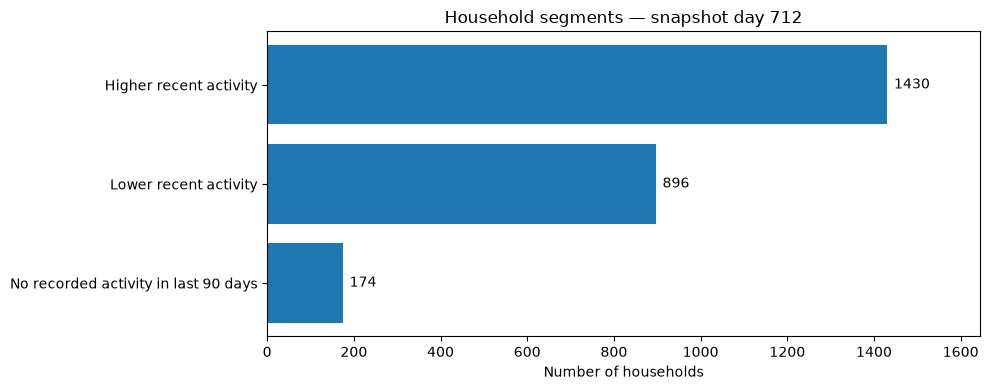

In [12]:
import matplotlib.pyplot as plt

segment_counts = household_segments["segment"].value_counts()

fig, ax = plt.subplots(figsize=(10, 4))

bars = ax.barh(segment_counts.index, segment_counts.values)
ax.invert_yaxis()
ax.bar_label(bars, padding=5)
ax.set_xlabel("Number of households")
ax.set_title(f"Household segments — snapshot day {snapshot_day}")
ax.margins(x=0.15)

fig.tight_layout()

chart_folder = project_root / "reports" / "segmentation"
chart_folder.mkdir(parents=True, exist_ok=True)

fig.savefig(
    chart_folder / "segment_sizes.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

In [13]:
cluster_comparison.to_csv(
    chart_folder / "cluster_count_comparison.csv",
    index=False
)

segment_profiles = (
    household_segments.groupby("segment")
    .agg(
        households=("baskets_90d", "size"),
        median_recency_days=("recency_days_90d", "median"),
        median_active_days=("active_days_90d", "median"),
        median_retailer_sales=("retailer_sales_90d", "median")
    )
)

segment_profiles.to_csv(
    chart_folder / "segment_profiles.csv",
    index=True
)

print("Saved cluster-count comparison and segment profiles.")

Saved cluster-count comparison and segment profiles.
